# Organizing the public Python library


This Julia companion examines the public structure and design choices in RiskLabAI 3.2.0. It reads relative source names and exact public declarations from the installed package, constructs the tables and figures, and exercises the corresponding Julia component interface. These are software structure and construction checks. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("A_risklabai_design");
using CSV, TOML
using RiskLabAI.Components
source_root = joinpath("..","data","appendix_public_sources")
public_inputs = TOML.parsefile(joinpath(source_root,"inputs.toml"))
module_path = joinpath(source_root,"python_module_inventory.csv")
source_inventory = CSV.read(module_path,DataFrame)
public_names = public_inputs["public_names"]
public_areas = filter(!=("__version__"),public_names)
source_modules = source_inventory[!,"Public source module"]
declarations = public_inputs["declarations"]
root_source = declarations["root"]["declaration"]*public_inputs["public_names_declaration"]
@assert public_inputs["python_version"]=="3.2.0"
for record in values(declarations)
    rows = source_inventory[source_inventory[!,"Public source module"].==record["path"],:]
    @assert nrow(rows) == 1
end
violet,muted = "#C084FC","#94A3B8"
function rendered_value(value)
    value isa Bool && return value ? "Pass" : "Fail"
    value isa Integer && return string(value)
    value isa AbstractFloat && isinteger(value) && return string(Int(value))
    return string(value)
end
function table(frame,name,caption)
    shown = copy(frame)
    save_table(shown,paths,name;caption,label="tab:appendix-"*replace(name,"_"=>"-"))
    return nothing
end
function box!(figure,x,y,width,height,label;color=palette.cyan,edge=color,textcolor=palette.text)
    plot!(figure,Shape(x.+[-width/2,width/2,width/2,-width/2],y.+[-height/2,-height/2,height/2,height/2]);color,linecolor=edge,label="",linewidth=1.3)
    annotate!(figure,x,y,text(label,10,textcolor,:center))
    return nothing
end


box! (generic function with 1 method)

## Public entry points


In [2]:
structure = DataFrame("Design choice"=>["One public front door","Modules loaded when requested","Grouped subject areas","Released implementation"],"Public evidence"=>["RiskLabAI.__all__","Module __getattr__",string(length(public_areas))*" exported areas",string(length(source_modules))*" Python source modules"],"Purpose"=>["Shows supported starting points","Delays optional and heavier imports","Keeps related methods together","Provides the concrete calculations"])
table(structure,"python_public_structure","Public organization of RiskLabAI 3.2.0.")
public_area_table = DataFrame("Public area"=>public_areas)
table(public_area_table,"python_public_areas","Root areas exposed by RiskLabAI 3.2.0.")


Row,Design choice,Public evidence,Purpose
,String,String,String
1,One public front door,RiskLabAI.__all__,Shows supported starting points
2,Modules loaded when requested,Module __getattr__,Delays optional and heavier imports
3,Grouped subject areas,12 exported areas,Keeps related methods together
4,Released implementation,144 Python source modules,Provides the concrete calculations


Row,Public area
,String
1,backtest
2,causal_factor_analysis
3,cluster
4,controller
5,core
6,data
7,ensemble
8,features
9,hpc


## Seeing the library as a public front door


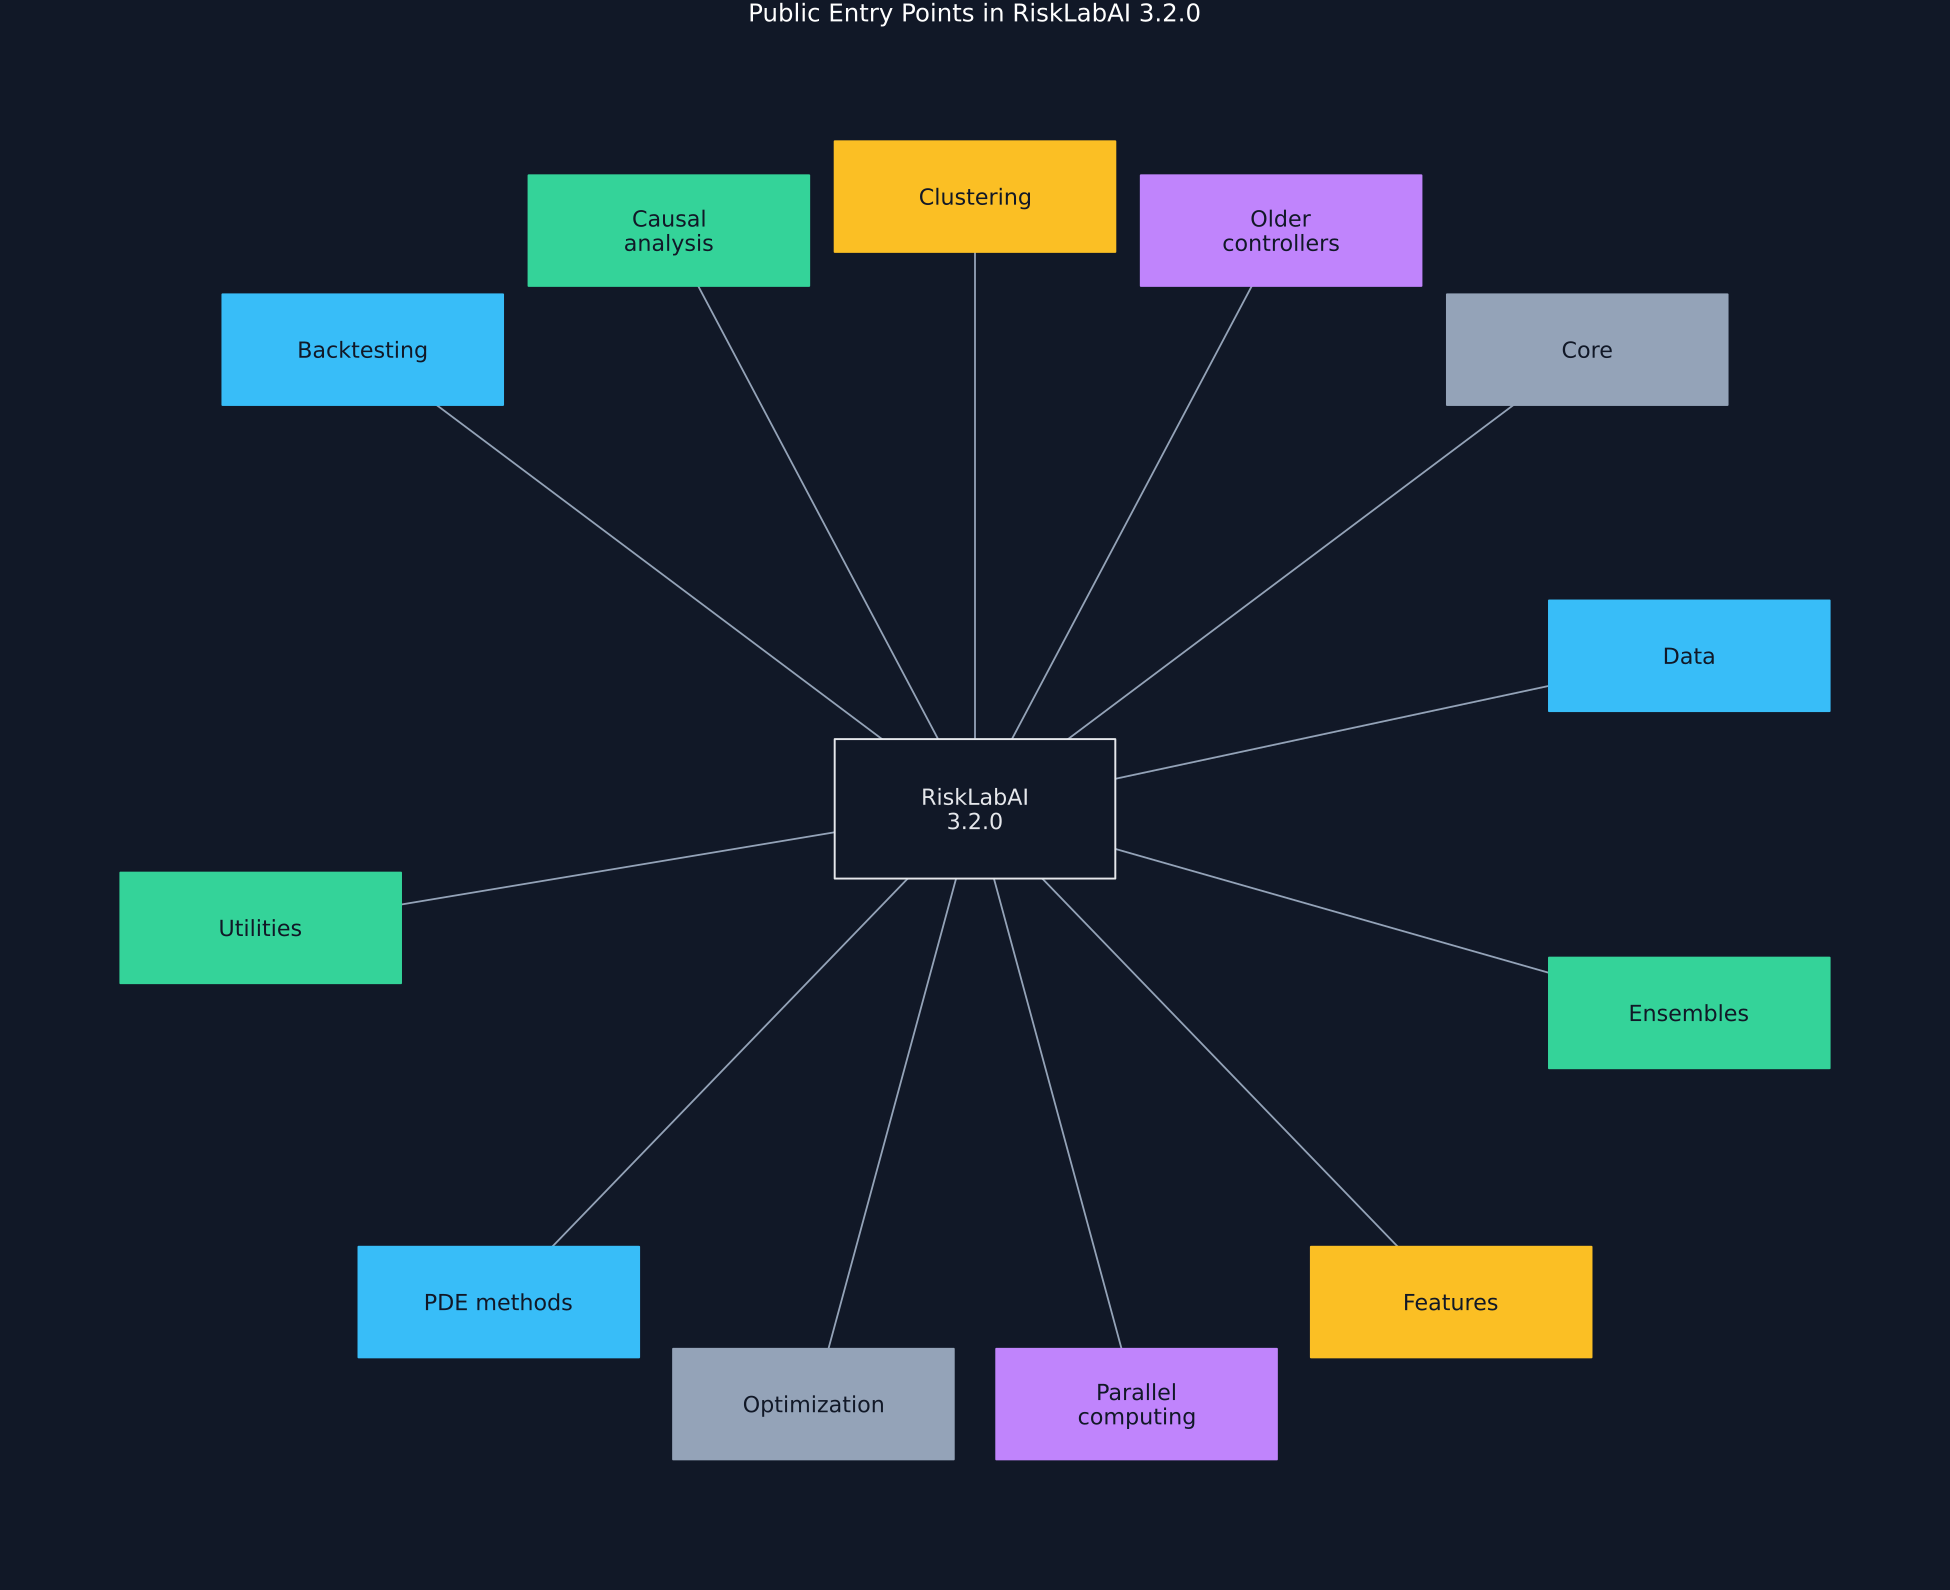

In [3]:
readable = Dict("backtest"=>"Backtesting","causal_factor_analysis"=>"Causal analysis","cluster"=>"Clustering","controller"=>"Older controllers","core"=>"Core","data"=>"Data","ensemble"=>"Ensembles","features"=>"Features","hpc"=>"Parallel computing","optimization"=>"Optimization","pde"=>"PDE methods","utils"=>"Utilities")
coordinates = [(-3.6,2.7),(-1.8,3.4),(0.,3.6),(1.8,3.4),(3.6,2.7),(4.2,.9),(4.2,-1.2),(2.8,-2.9),(.95,-3.5),(-.95,-3.5),(-2.8,-2.9),(-4.2,-.7)]
topology = DataFrame("Public area"=>public_areas,"Label"=>[readable[name] for name in public_areas],"X"=>first.(coordinates),"Y"=>last.(coordinates))
save_data(topology,paths,"python_public_topology")
figure = plot(;xlims=(-5.4,5.4),ylims=(-4.35,4.35),aspect_ratio=:equal,axis=false,ticks=false,grid=false,legend=false,title="Public Entry Points in RiskLabAI 3.2.0",size=(1300,1060))
for row in eachrow(topology)
    plot!(figure,[0,row.X],[0,row.Y];color=muted,linewidth=1.2,label="")
end
for (index,row) in enumerate(eachrow(topology))
    color = [palette.cyan,palette.green,palette.amber,violet,muted][mod1(index,5)]
    label = replace(row.Label,"Causal analysis"=>"Causal\nanalysis","Older controllers"=>"Older\ncontrollers","Parallel computing"=>"Parallel\ncomputing")
    box!(figure,row.X,row.Y,1.65,.65,label;color,textcolor=palette.background)
end
box!(figure,0,0,1.65,.82,"RiskLabAI\n3.2.0";color=palette.background,edge=palette.text)
save_figure(figure,paths,"python_public_topology")


## Tests


In [4]:
@assert occursin("def __getattr__",root_source)
@assert !isempty(public_areas)
@assert allunique(public_areas)
@assert all(any(startswith(path,area*"/") for path in source_modules) || occursin(area,root_source) for area in public_areas)
@assert length(source_modules)>=100
